# RanPAC Phase 2 · Ridge không random projection

Dùng embedding gốc `H = F` để tích lũy `G = HᵀH` và `C = HᵀY`. Sau mỗi task, chọn λ bằng MSE trên 20% train của task hiện tại rồi giải `(G + λI) W_out = C` từ thống kê tích lũy. Mốc `A[10]` trong Table 1 là **87,0%**. [Table 1](https://arxiv.org/pdf/2307.02251v3#page=9)

Cả ba notebook dùng Split CIFAR-100 với seed 1993 và 10 task, mỗi task 10 lớp. Sau task `t`, model dự đoán trên toàn bộ `10t` lớp đã thấy. ID task chỉ dùng để nhóm kết quả test.


## 1. Cài thư viện và mở mã dùng chung

Đặt `ranpac_core.py`, `ranpac_data.py`, `ranpac_colab.py` và `test_ranpac_core.py` trong thư mục `MyDrive/RanPAC_implement`. Mở notebook này bằng Colab. Sửa `SOURCE_DIR` nếu đã đặt mã ở thư mục khác.

Các cell setup và smoke test chạy được trên CPU. Chọn GPU runtime cho cell thí nghiệm. PyTorch và torchvision lấy từ runtime Colab. Config lưu phiên bản thực tế của thư viện.


In [1]:
%pip install -q timm==1.0.22 wandb==0.31.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount('/content/drive')
SOURCE_DIR = Path('/content/drive/MyDrive/RanPAC_implement')
WORK_DIR = Path('/content/drive/MyDrive/ranpac-runs')
if not (SOURCE_DIR / 'src' / 'ranpac_colab.py').is_file():
    raise FileNotFoundError(f'Chưa tìm thấy mã nguồn tại {SOURCE_DIR}')
sys.path.insert(0, str(SOURCE_DIR / 'src'))

from ranpac_colab import run_phase2, smoke_wandb


Mounted at /content/drive


## 2. Chọn chế độ chạy

Điền `WANDB_ENTITY` bằng slug tài khoản hoặc team có quyền ghi. Thêm `WANDB_API_KEY` trong **Colab Secrets** và bật quyền truy cập notebook. `WORK_DIR` chứa checkpoint và cache embedding dùng chung.

Mặc định chạy đến task 2. Để thử resume, lần đầu đặt `STOP_AFTER_TASK = 1`. Sau đó đặt `RESUME = True`, `STOP_AFTER_TASK = 2` và giữ nguyên tên run, preset cùng các tham số còn lại. Khi pilot đạt, tiếp tục cùng checkpoint với `STOP_AFTER_TASK = 10`. Dùng `RUN_LABEL` mới cho một lần chạy độc lập.


In [3]:
PRESET = 'ridge'
WANDB_ENTITY = 'pnp123'
WANDB_PROJECT = 'ML'
WANDB_MODE = 'online'
RUN_LABEL = 'main'
STOP_AFTER_TASK = 10
RESUME = False
BATCH_SIZE = 48
NUM_WORKERS = 2
STATS_DEVICE = 'cpu'


## 3. Kiểm tra trên CPU

Chạy test chia lớp, CIL, cộng dồn, chọn λ và khôi phục trạng thái. Với lần thiết lập W&B đầu tiên, bật `RUN_WANDB_SMOKE` rồi mở URL in ra để kiểm tra `smoke/ok = 1` trong project đã chọn.


In [4]:
import unittest

suite = unittest.defaultTestLoader.loadTestsFromName('test_ranpac_core')
result = unittest.TextTestRunner(verbosity=2).run(suite)
if not result.wasSuccessful():
    raise AssertionError('Kiểm tra CPU chưa đạt')


test_class_order_and_remapping (test_ranpac_core.Phase2Tests.test_class_order_and_remapping) ... ok
test_ncm_uses_all_seen_classes_for_each_test_shard (test_ranpac_core.Phase2Tests.test_ncm_uses_all_seen_classes_for_each_test_shard) ... ok
test_primal_and_dual_lambda_selection_match_direct_solution (test_ranpac_core.Phase2Tests.test_primal_and_dual_lambda_selection_match_direct_solution) ... ok
test_ridge_accumulation_and_resume_match_joint_solve (test_ranpac_core.Phase2Tests.test_ridge_accumulation_and_resume_match_joint_solve) ... ok

----------------------------------------------------------------------
Ran 4 tests in 5.580s

OK


In [5]:
RUN_WANDB_SMOKE = False
if RUN_WANDB_SMOKE:
    smoke_wandb(WANDB_ENTITY, WANDB_PROJECT)


## 4. Chạy và lưu kết quả

Sau mỗi task, chương trình lưu thống kê, run ID W&B và metrics trên Drive rồi log lên dashboard. `metrics.csv` chứa `A[t]`, λ và chi phí. `accuracy_matrix.csv` chứa `R[t,i]`. Các số mốc paper dùng để đối chiếu sau đủ 10 task.

Nếu cần chạy offline, đặt `WANDB_MODE = 'offline'` trước khi khởi tạo. Thư mục log được in khi chạy và nằm trong thư mục run trên Drive. Khi có mạng, xác thực và chạy `wandb sync <offline-run-directory>` cho từng đoạn theo thứ tự. Xác nhận run đã có trên dashboard trước khi resume online. [Hướng dẫn sync](https://docs.coreweave.com/products/wandb/ref/cli/wandb-sync)


In [6]:
records = run_phase2(
    PRESET, WORK_DIR, entity=WANDB_ENTITY, project=WANDB_PROJECT,
    stop_after_task=STOP_AFTER_TASK, run_label=RUN_LABEL, resume=RESUME,
    wandb_mode=WANDB_MODE, batch_size=BATCH_SIZE, workers=NUM_WORKERS,
    stats_device=STATS_DEVICE,
)


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: nphuongpham172 (pnp123) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


W&B run 234796d5b67948f5a8353592ca8378ce: https://forge.coreweave.com/wandb/pnp123/RanPAC-reproduction/runs/234796d5b67948f5a8353592ca8378ce
Results: /content/drive/MyDrive/ranpac-runs/runs/ridge-s1993-main
Task 01/10 | A[1] = 97.80% | 6.5s
Task 02/10 | A[2] = 95.50% | 3.2s
Task 03/10 | A[3] = 94.53% | 3.1s
Task 04/10 | A[4] = 92.80% | 2.7s
Task 05/10 | A[5] = 91.50% | 3.0s
Task 06/10 | A[6] = 90.37% | 3.0s
Task 07/10 | A[7] = 90.00% | 3.3s
Task 08/10 | A[8] = 88.30% | 3.6s
Task 09/10 | A[9] = 87.46% | 3.5s
Task 10/10 | A[10] = 87.02% | 3.3s
Table 1 | A[10] 87.02% | paper 87.0% | Δ +0.02 pp


phase2/avg_accuracy_pct,█▇▆▅▄▃▃▂▁▁
phase2/eval_seconds,▁▁▁▂▄▃▄▄██
phase2/feature_seconds,▁▁▁▁▁▁▁▁▁▁
phase2/fit_seconds,▃▂▁▁█▁▁▁█▂
phase2/gpu_peak_allocated_mib,▁▁▁▁▁▁▁▁▁▁
phase2/host_peak_rss_mib,▁█████████
phase2/lambda_search_seconds,▃▂▁▁█▁▁▁█▃
phase2/ridge_lambda,▁▁▁▁▁▁▁▁▁▁
phase2/ridge_solve_seconds,▃▄▂▁▆▁▂▂█▂
phase2/seen_classes,▁▂▃▃▄▅▆▆▇█
+2,...


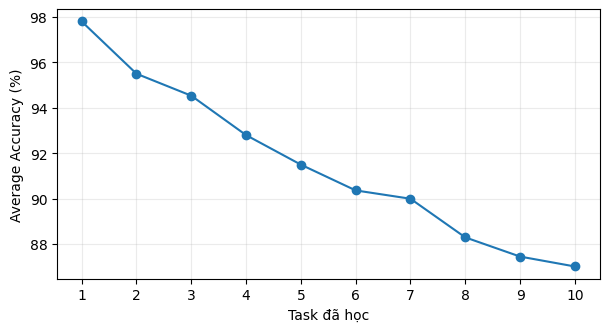

In [7]:
import matplotlib.pyplot as plt

tasks = [row['task'] for row in records]
accuracies = [row['avg_accuracy_pct'] for row in records]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tasks, accuracies, marker='o')
ax.set(xlabel='Task đã học', ylabel='Average Accuracy (%)', xticks=tasks)
ax.grid(alpha=0.25)
plt.show()
